# ⚙️ Machine Failure Prediction — End-to-End ML Pipeline

This notebook builds a predictive maintenance model that predicts whether an industrial machine will **fail** based on real-time sensor readings, using the **AI4I 2020 Predictive Maintenance Dataset** (UCI Machine Learning Repository, 10,000 samples from a milling machine simulation).

**Steps covered:**
1. Import libraries
2. Load & inspect the dataset
3. Exploratory Data Analysis (EDA) with visualizations
4. Data preprocessing & feature engineering (leakage-safe)
5. Handling class imbalance & train/test split
6. Model training (multiple classifiers compared)
7. Model evaluation (precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix)
8. Feature importance analysis
9. Saving the final model & scaler for the Streamlit app


## 1. Import Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load & Inspect the Dataset

The **AI4I 2020 Predictive Maintenance Dataset** simulates a milling machine with real-world sensor readings and 5 independent failure modes (Tool Wear, Heat Dissipation, Power, Overstrain, Random Failure). We predict the overall binary `Machine failure` label.

In [6]:
df = pd.read_csv("ai4i2020.csv")
df.columns = [c.strip() for c in df.columns]

print("Shape:", df.shape)
print("\nFailure rate: {:.2f}%".format(df["Machine failure"].mean() * 100))
df.head()

Shape: (10000, 14)

Failure rate: 3.39%


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [7]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum().sum(), "total missing values")
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Class Balance — Machine Failure

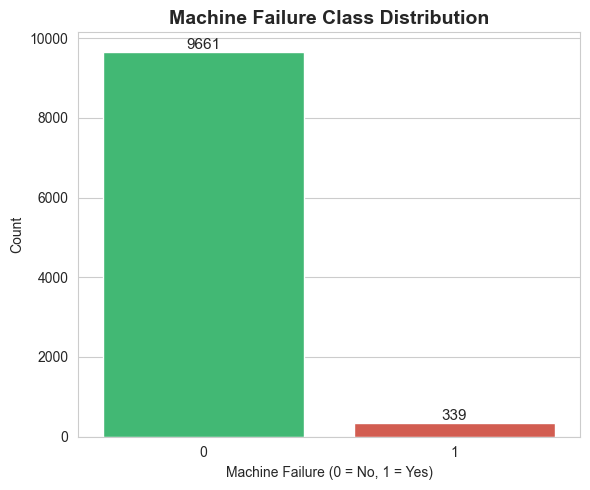

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

⚠️ Dataset is highly imbalanced — failures are rare events, as in real-world maintenance data.


In [8]:
plt.figure(figsize=(6, 5))
ax = sns.countplot(data=df, x="Machine failure", palette=["#2ecc71", "#e74c3c"])
plt.title("Machine Failure Class Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.tight_layout()
plt.savefig("class_balance.png", dpi=150)
plt.show()

print(df["Machine failure"].value_counts(normalize=True) * 100)
print("\n⚠️ Dataset is highly imbalanced — failures are rare events, as in real-world maintenance data.")

### 3.2 Failure Breakdown by Mode

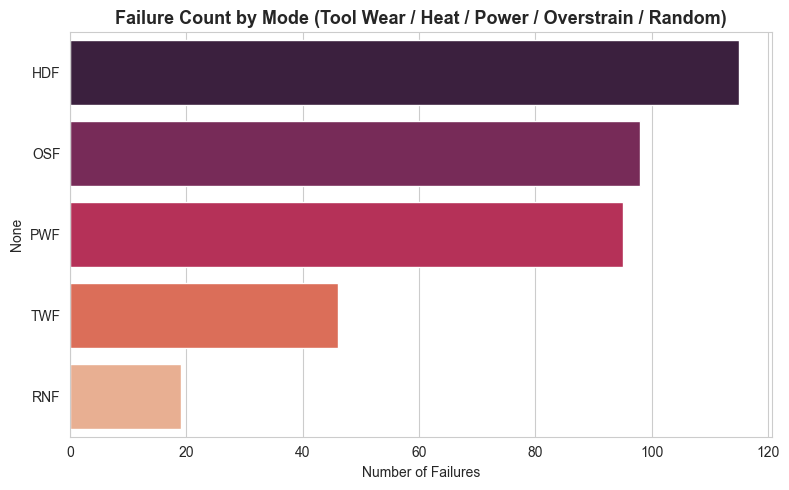

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [9]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
mode_counts = df[failure_modes].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=mode_counts.values, y=mode_counts.index, palette="rocket")
plt.title("Failure Count by Mode (Tool Wear / Heat / Power / Overstrain / Random)", fontsize=13, fontweight="bold")
plt.xlabel("Number of Failures")
plt.tight_layout()
plt.savefig("failure_modes.png", dpi=150)
plt.show()

mode_counts

### 3.3 Sensor Distributions by Failure Status

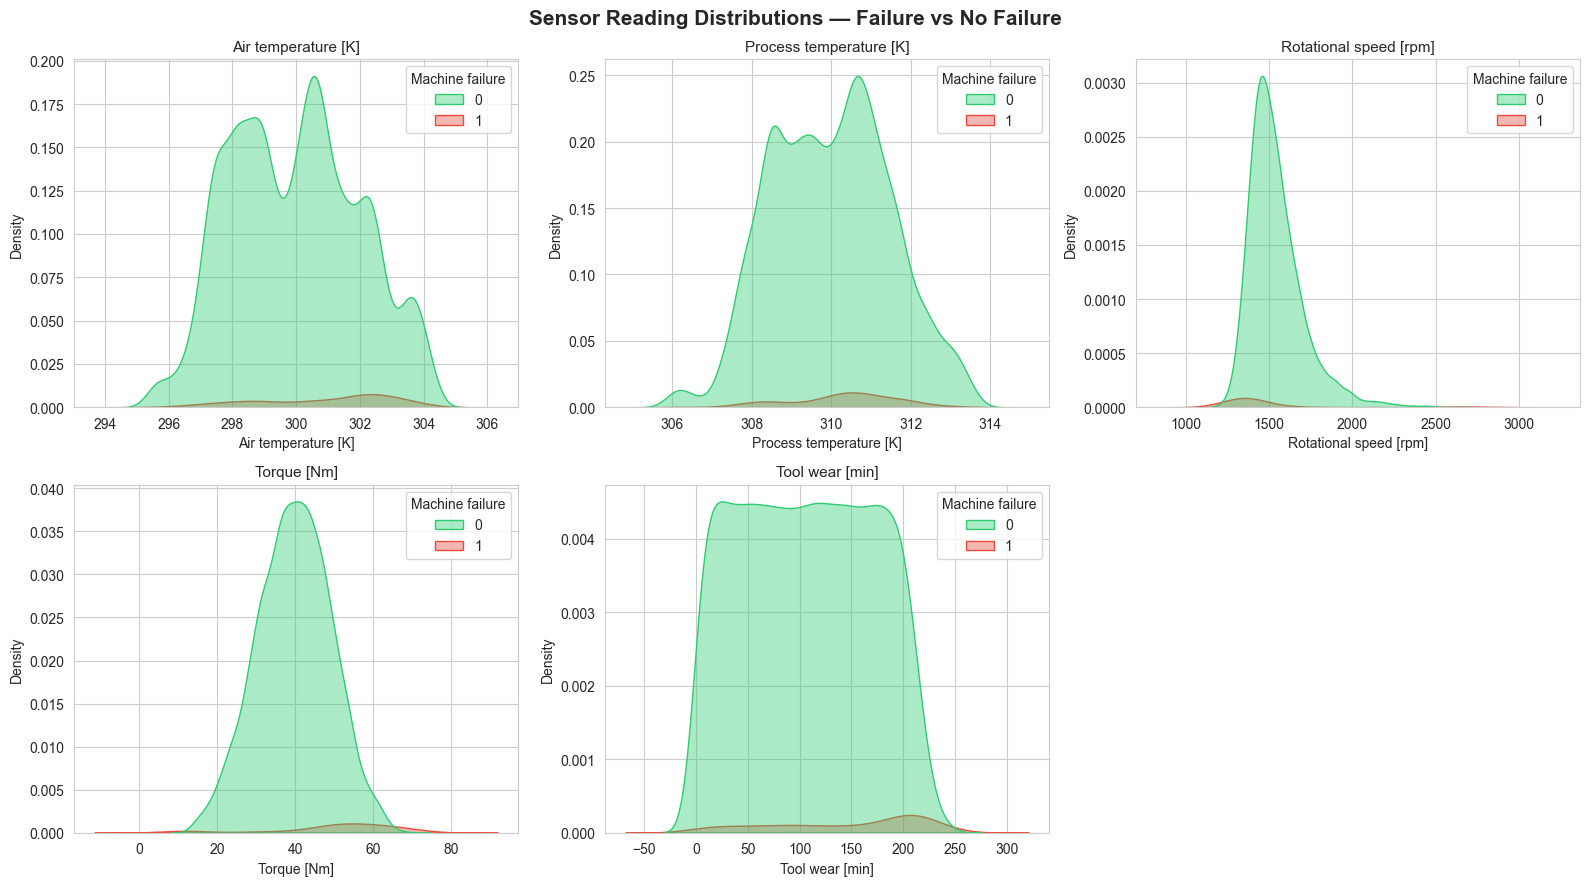

In [10]:
sensor_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
               "Torque [Nm]", "Tool wear [min]"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), sensor_cols):
    sns.kdeplot(data=df, x=col, hue="Machine failure", fill=True, alpha=0.4, ax=ax,
                palette=["#2ecc71", "#e74c3c"])
    ax.set_title(col, fontsize=11)
axes.flatten()[-1].axis("off")

plt.suptitle("Sensor Reading Distributions — Failure vs No Failure", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("sensor_distributions.png", dpi=150)
plt.show()

### 3.4 Machine Type vs Failure Rate

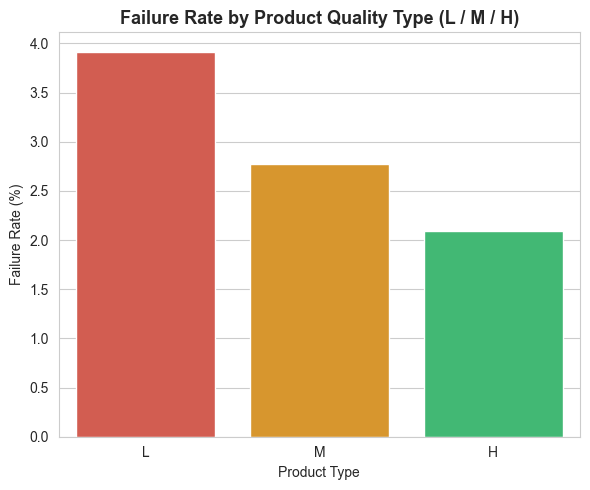

Type
L    3.916667
M    2.769436
H    2.093719
Name: Machine failure, dtype: float64

In [11]:
type_failure = df.groupby("Type")["Machine failure"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(6, 5))
sns.barplot(x=type_failure.index, y=type_failure.values, palette=["#e74c3c", "#f39c12", "#2ecc71"])
plt.title("Failure Rate by Product Quality Type (L / M / H)", fontsize=13, fontweight="bold")
plt.ylabel("Failure Rate (%)")
plt.xlabel("Product Type")
plt.tight_layout()
plt.savefig("failure_by_type.png", dpi=150)
plt.show()

type_failure

### 3.5 Correlation Heatmap (Sensor Features)

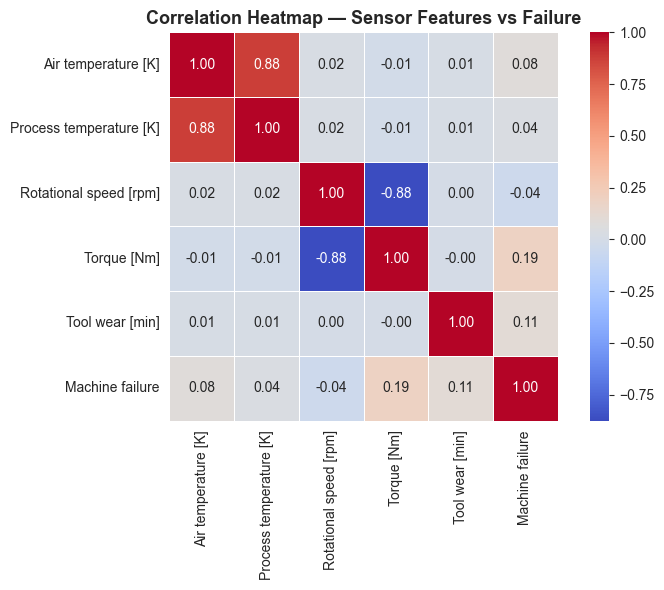

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[sensor_cols + ["Machine failure"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            square=True, linewidths=0.5)
plt.title("Correlation Heatmap — Sensor Features vs Failure", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

### 3.6 Torque vs Rotational Speed (colored by failure)

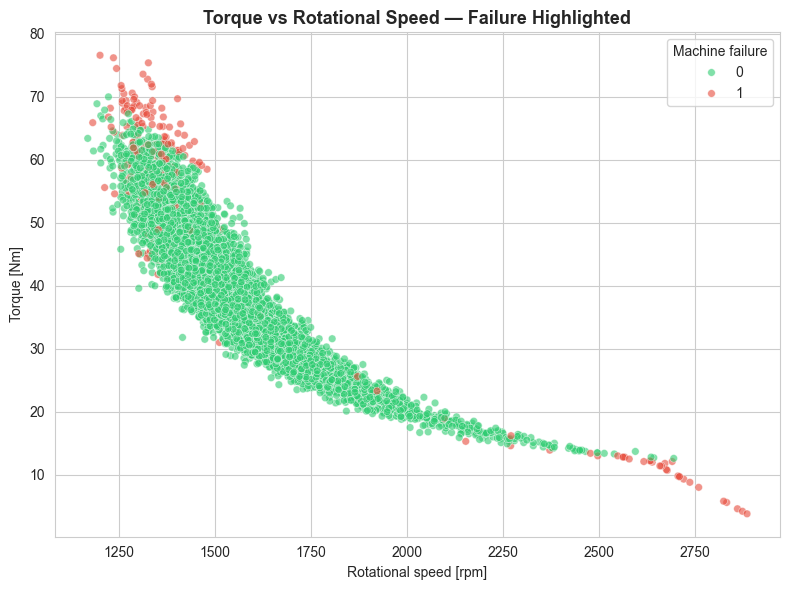

In [13]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Rotational speed [rpm]", y="Torque [Nm]", hue="Machine failure",
                 palette=["#2ecc71", "#e74c3c"], alpha=0.6, s=30)
plt.title("Torque vs Rotational Speed — Failure Highlighted", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("torque_vs_speed.png", dpi=150)
plt.show()

## 4. Data Preprocessing & Feature Engineering

**Important — avoiding data leakage:** The columns `TWF`, `HDF`, `PWF`, `OSF`, `RNF` are the individual failure-mode flags that directly *define* whether `Machine failure` = 1. Including them as model inputs would leak the answer, so they are **dropped** before training (they were only used above to explore *why* machines failed).

We also engineer two physically meaningful features:
- **Power [W]** ≈ Torque × Rotational speed (converted to rad/s) — mechanical power delivered
- **Temperature difference [K]** = Process temperature − Air temperature — a known driver of Heat Dissipation Failures

`Type` (L/M/H) is label-encoded since it's ordinal in quality tier.

In [14]:
model_df = df.copy()

# Feature engineering
model_df["Power [W]"] = model_df["Torque [Nm]"] * (model_df["Rotational speed [rpm]"] * 2 * np.pi / 60)
model_df["Temp difference [K]"] = model_df["Process temperature [K]"] - model_df["Air temperature [K]"]

# Encode machine type
type_encoder = LabelEncoder()
model_df["Type_encoded"] = type_encoder.fit_transform(model_df["Type"])  # H=0, L=1, M=2 (alphabetical)
print("Type encoding:", dict(zip(type_encoder.classes_, type_encoder.transform(type_encoder.classes_))))

feature_cols = [
    "Type_encoded", "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
    "Power [W]", "Temp difference [K]",
]

X = model_df[feature_cols]
y = model_df["Machine failure"]

print("\nFinal feature set:", feature_cols)
X.head()

Type encoding: {'H': np.int64(0), 'L': np.int64(1), 'M': np.int64(2)}

Final feature set: ['Type_encoded', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Power [W]', 'Temp difference [K]']


,Type_encoded,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Power [W],Temp difference [K]
0,2,298.1,308.6,1551,42.8,0,6951.590560,10.5
1,1,298.2,308.7,1408,46.3,3,6826.722724,10.5
2,1,298.1,308.5,1498,49.4,5,7749.387543,10.4
3,1,298.2,308.6,1433,39.5,7,5927.504659,10.4
4,1,298.2,308.7,1408,40.0,9,5897.816608,10.5


## 5. Train/Test Split & Scaling

We use a **stratified split** to preserve the failure-rate ratio in both train and test sets, which is essential given the class imbalance.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0], f"| Failures: {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print("Testing samples: ", X_test.shape[0], f"| Failures: {y_test.sum()} ({y_test.mean()*100:.2f}%)")

Training samples: 8000 | Failures: 271 (3.39%)
Testing samples:  2000 | Failures: 68 (3.40%)


## 6. Model Training

Because failures are rare (~3.4%), we use **`class_weight='balanced'`** so models don't just predict "no failure" for everything. We train and compare:
- Logistic Regression
- Random Forest
- Gradient Boosting

Given the imbalance, we select the best model by **F1-score** (balances precision & recall) rather than raw accuracy.

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42),
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results[name] = {
        "model": model,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "pr_auc": average_precision_score(y_test, y_proba),
        "y_pred": y_pred,
        "y_proba": y_proba,
    }
    r = results[name]
    print(f"{name:20s} | Precision: {r['precision']:.3f} | Recall: {r['recall']:.3f} | "
          f"F1: {r['f1']:.3f} | ROC-AUC: {r['roc_auc']:.3f} | PR-AUC: {r['pr_auc']:.3f}")

Logistic Regression  | Precision: 0.181 | Recall: 0.882 | F1: 0.300 | ROC-AUC: 0.933 | PR-AUC: 0.473
Random Forest        | Precision: 0.940 | Recall: 0.691 | F1: 0.797 | ROC-AUC: 0.976 | PR-AUC: 0.853
Gradient Boosting    | Precision: 0.915 | Recall: 0.794 | F1: 0.850 | ROC-AUC: 0.973 | PR-AUC: 0.887


### 6.1 Model Comparison Chart

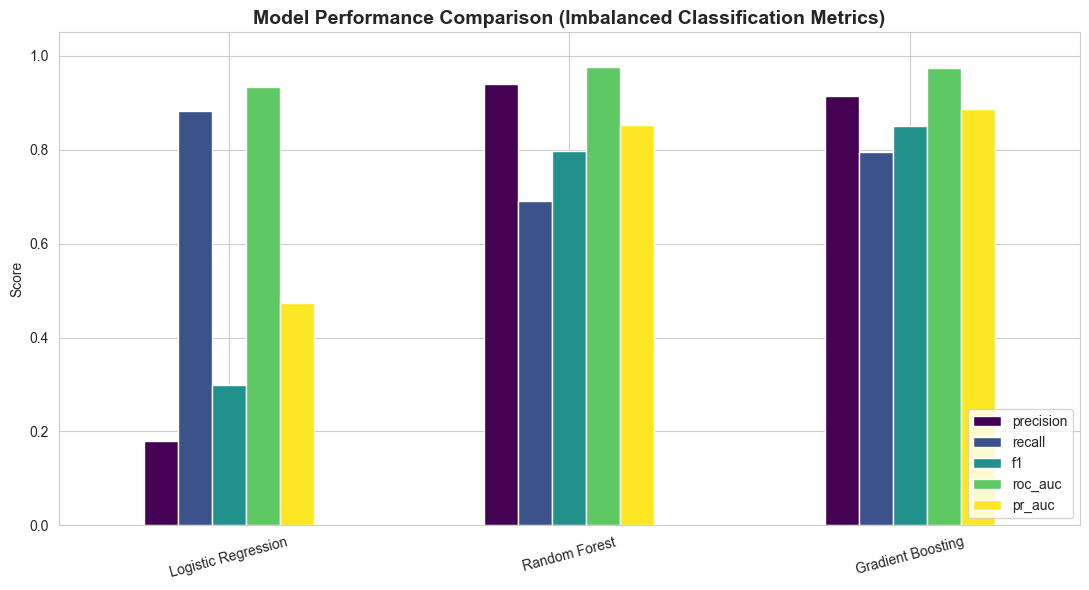

,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.180723,0.882353,0.300000,0.932986,0.473279
Random Forest,0.940000,0.691176,0.796610,0.976362,0.852624
Gradient Boosting,0.915254,0.794118,0.850394,0.973245,0.887388


In [17]:
results_df = pd.DataFrame(results).T[["precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float)

results_df.plot(kind="bar", figsize=(11, 6), colormap="viridis")
plt.title("Model Performance Comparison (Imbalanced Classification Metrics)", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

results_df

In [18]:
best_model_name = results_df["f1"].idxmax()
best_model = results[best_model_name]["model"]
best_pred = results[best_model_name]["y_pred"]
best_proba = results[best_model_name]["y_proba"]
print(f"Best model selected (by F1-score): {best_model_name}")

Best model selected (by F1-score): Gradient Boosting


## 7. Detailed Evaluation of the Best Model

In [19]:
print(f"=== {best_model_name} — Classification Report ===\n")
print(classification_report(y_test, best_pred, target_names=["No Failure", "Failure"]))

=== Gradient Boosting — Classification Report ===

              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      1932
     Failure       0.92      0.79      0.85        68

    accuracy                           0.99      2000
   macro avg       0.95      0.90      0.92      2000
weighted avg       0.99      0.99      0.99      2000



### 7.1 Confusion Matrix

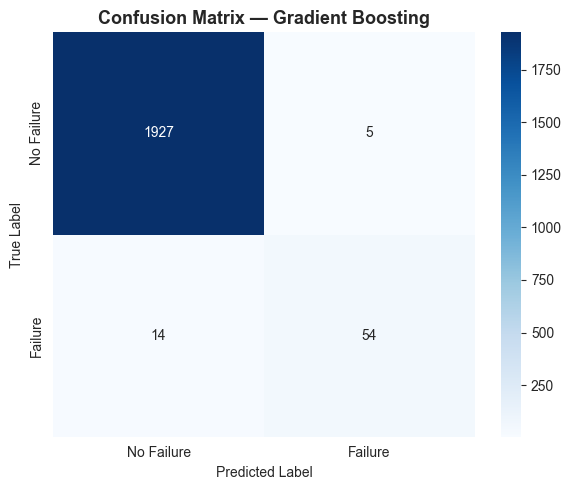

In [20]:
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.title(f"Confusion Matrix — {best_model_name}", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

### 7.2 ROC Curve

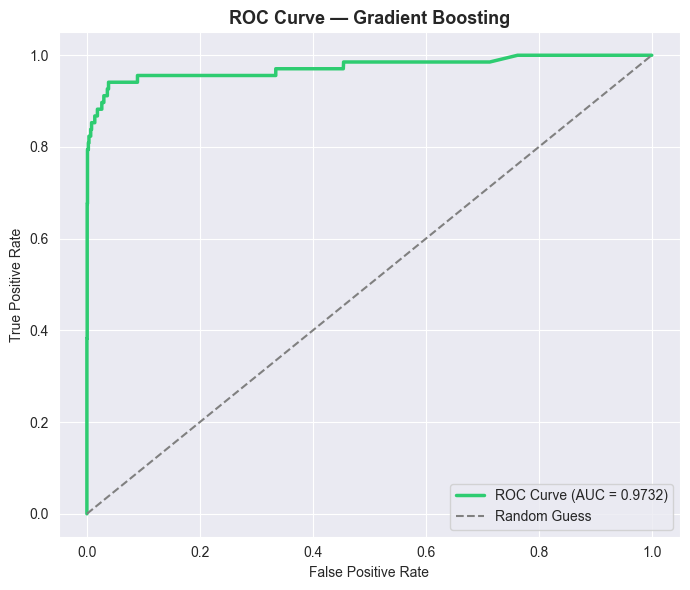

In [21]:
fpr, tpr, _ = roc_curve(y_test, best_proba)
auc_score = roc_auc_score(y_test, best_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="#2ecc71", linewidth=2.5, label=f"ROC Curve (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.title(f"ROC Curve — {best_model_name}", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

### 7.3 Precision-Recall Curve (more informative than ROC for imbalanced data)

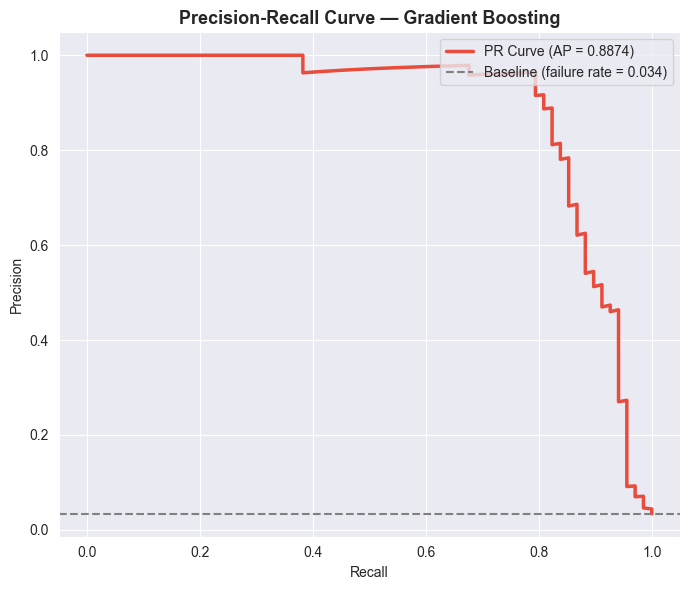

In [22]:
precision_vals, recall_vals, _ = precision_recall_curve(y_test, best_proba)
pr_auc = average_precision_score(y_test, best_proba)

plt.figure(figsize=(7, 6))
plt.plot(recall_vals, precision_vals, color="#e74c3c", linewidth=2.5, label=f"PR Curve (AP = {pr_auc:.4f})")
baseline = y_test.mean()
plt.axhline(baseline, linestyle="--", color="gray", label=f"Baseline (failure rate = {baseline:.3f})")
plt.title(f"Precision-Recall Curve — {best_model_name}", fontsize=13, fontweight="bold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("pr_curve.png", dpi=150)
plt.show()

## 8. Feature Importance

Which sensor readings drive the failure prediction most?

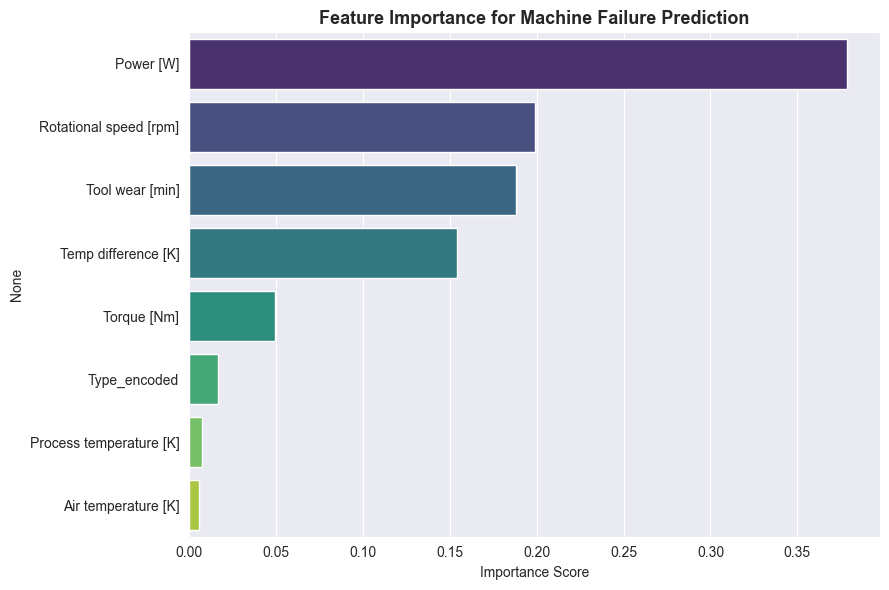

Power [W]                  0.378614
Rotational speed [rpm]     0.198825
Tool wear [min]            0.188397
Temp difference [K]        0.154449
Torque [Nm]                0.049631
Type_encoded               0.016478
Process temperature [K]    0.007655
Air temperature [K]        0.005951
dtype: float64

In [23]:
if hasattr(best_model, "feature_importances_"):
    importance_model = best_model
else:
    importance_model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
    importance_model.fit(X_train_scaled, y_train)

importances = pd.Series(importance_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Feature Importance for Machine Failure Prediction", fontsize=13, fontweight="bold")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

importances

## 9. Save the Final Model & Scaler

We persist the trained model, scaler, type encoder, and feature metadata using `joblib` for the Streamlit app.

In [24]:
import os
os.makedirs("model", exist_ok=True)

joblib.dump(best_model, "model/failure_model.pkl")
joblib.dump(scaler, "model/scaler.pkl")
joblib.dump(type_encoder, "model/type_encoder.pkl")
joblib.dump(feature_cols, "model/feature_names.pkl")

feature_stats = X.describe().T[["min", "max", "mean"]]
joblib.dump(feature_stats, "model/feature_stats.pkl")

print("Saved:")
print(" - model/failure_model.pkl   (trained classifier)")
print(" - model/scaler.pkl          (StandardScaler)")
print(" - model/type_encoder.pkl    (LabelEncoder for machine Type)")
print(" - model/feature_names.pkl   (ordered feature list)")
print(" - model/feature_stats.pkl   (min/max/mean per feature, for UI sliders)")
r = results[best_model_name]
print(f"\nFinal model: {best_model_name} | F1: {r['f1']:.4f} | Precision: {r['precision']:.4f} | "
      f"Recall: {r['recall']:.4f} | ROC-AUC: {r['roc_auc']:.4f}")

Saved:
 - model/failure_model.pkl   (trained classifier)
 - model/scaler.pkl          (StandardScaler)
 - model/type_encoder.pkl    (LabelEncoder for machine Type)
 - model/feature_names.pkl   (ordered feature list)
 - model/feature_stats.pkl   (min/max/mean per feature, for UI sliders)

Final model: Gradient Boosting | F1: 0.8504 | Precision: 0.9153 | Recall: 0.7941 | ROC-AUC: 0.9732


---
## ✅ Summary

- Loaded the AI4I 2020 Predictive Maintenance Dataset (10,000 samples, real UCI benchmark).
- Explored class imbalance, failure modes, sensor distributions, and correlations.
- Engineered `Power` and `Temperature difference` features; dropped leakage-prone failure-mode flags.
- Used a stratified split and `class_weight='balanced'` to handle the ~3.4% failure rate.
- Trained and compared Logistic Regression, Random Forest, and Gradient Boosting.
- Evaluated with precision, recall, F1, ROC-AUC, and PR-AUC (more meaningful than accuracy here).
- Identified the most influential sensor readings.
- Saved the trained model + scaler + encoder for the companion **Streamlit app** (`app.py`).
